# Predicción de deserción de clientes con umbral de decisión calibrado
## Grupo 7 · Inteligencia Artificial (1INF24)

El objetivo es comparar una regresión logística y un árbol de decisión (CART) para estimar la probabilidad
de que un cliente cancele su servicio, y analizar qué ocurre cuando el umbral estándar de 0,50 se reemplaza
por un umbral $\tau^*$ calibrado con validación cruzada sobre el conjunto de entrenamiento.

La hipótesis es que el umbral calibrado aumenta el recall en el conjunto de prueba sin que la precisión
caiga más de 5 puntos porcentuales. Cada modelo se evalúa en prueba una sola vez, sin reajustar nada después
de ver sus resultados.

El trabajo se organiza en seis experimentos:

| Experimento | Qué responde | Sección |
|---|---|---|
| E1 | Selección de hiperparámetros por validación cruzada (AUC) | 5 |
| E2 | Calibración del umbral $\tau^*$ y elección del modelo final | 6 |
| E3 | Evaluación en prueba: $\tau=0.5$ frente a $\tau^*$ | 7 |
| E4 | Comparación con técnicas de referencia y umbral restringido | 7 |
| E5 | Robustez en 10 particiones distintas | 7 |
| E6 | Desempeño por género y por condición de adulto mayor | 8 |

Las tablas y figuras se guardan en la carpeta `resultados/`.

# 1. Datos y limpieza

In [1]:
import json
import time
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

plt.style.use('ggplot')
pd.set_option('display.precision', 4)

In [2]:
%matplotlib inline

Fijamos la semilla en 42 para que todos los resultados sean reproducibles. Los umbrales candidatos van
de 0,10 a 0,90 en pasos de 0,01 (81 valores), el mismo rango que usa Cao (2026) en su trabajo sobre
deserción en telecomunicaciones.

In [3]:
SEED = 42
GRID_TAU = np.round(np.arange(0.10, 0.901, 0.01), 2)

carpeta_salida = Path('resultados')
carpeta_salida.mkdir(parents=True, exist_ok=True)

print('Umbrales candidatos:', len(GRID_TAU), f'(de {GRID_TAU[0]} a {GRID_TAU[-1]})')
print('Carpeta de salida:', carpeta_salida.resolve())

Umbrales candidatos: 81 (de 0.1 a 0.9)
Carpeta de salida: /home/claude/csvrun/resultados


Cargamos el conjunto de datos Telco Customer Churn de IBM desde `Telco_customer_churn.csv`, que debe estar
en la misma carpeta que este notebook. El archivo tiene 7,043 clientes y 33 columnas.

In [4]:
ruta_datos = Path('Telco_customer_churn.csv')
df_original = pd.read_csv(ruta_datos)
df = df_original.copy()

display(df.shape)
print(list(df.columns))

(7043, 33)

['CustomerID', 'Count', 'Country', 'State', 'City', 'Zip Code', 'Lat Long', 'Latitude', 'Longitude', 'Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Tenure Months', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method', 'Monthly Charges', 'Total Charges', 'Churn Label', 'Churn Value', 'Churn Score', 'CLTV', 'Churn Reason']


La variable objetivo es `Churn Value`, que vale 1 si el cliente canceló y 0 si permaneció. Como cada cliente
tiene una etiqueta conocida, se trata de un problema de clasificación binaria supervisada en el que la unidad
de análisis es el cliente.

In [5]:
y = df['Churn Value'].astype(int)

display(y.value_counts().rename('Clientes'))
print('Tasa de deserción:', round(y.mean(), 4))

Churn Value
0    5174
1    1869
Name: Clientes, dtype: int64

Tasa de deserción: 0.2654


# 2. Selección de entradas y partición

Antes de entrenar eliminamos las columnas que revelan la respuesta. `Churn Score` es el puntaje de un modelo
previo, `Churn Reason` solo existe para quienes ya cancelaron y `Churn Label` repite la etiqueta. Si las
dejáramos, el modelo obtendría la respuesta sin aprender nada del problema.

Tampoco usamos como entradas `CustomerID`, que es solo un identificador, ni `CLTV`, que reservamos para
priorizar clientes al final; ambas se guardan aparte para la sección 8. Por último, descartamos la ubicación
detallada (`City`, `Zip Code` y coordenadas), que tiene demasiados valores distintos, y las columnas que son
constantes (`Count`, `Country`, `State`). Quedan 19 variables de entrada.

In [6]:
ids = df['CustomerID']
cltv = df['CLTV']

columnas_excluidas = [
    'CustomerID', 'Churn Value', 'Churn Label', 'Churn Score', 'Churn Reason', 'CLTV',
    'Count', 'Country', 'State', 'City', 'Zip Code', 'Lat Long', 'Latitude', 'Longitude',
]
X = df.drop(columns=columnas_excluidas)

print('Entradas del modelo:', X.shape[1])
print(list(X.columns))

Entradas del modelo: 19
['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Tenure Months', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method', 'Monthly Charges', 'Total Charges']


`Total Charges` se lee como texto porque tiene 11 valores vacíos. Al revisarlos, todos corresponden a clientes
con antigüedad 0, que todavía no han realizado ningún pago, así que les asignamos 0. Como es una regla fija
que no aprende nada de los datos, puede aplicarse antes de dividir en entrenamiento y prueba.

In [7]:
X['Total Charges'] = pd.to_numeric(X['Total Charges'], errors='coerce')
n_vacios = int(X['Total Charges'].isna().sum())

print('Total Charges vacíos:', n_vacios)
display(X.loc[X['Total Charges'].isna(), 'Tenure Months'].value_counts().rename('Clientes por antigüedad'))
assert X.loc[X['Total Charges'].isna(), 'Tenure Months'].eq(0).all()

X['Total Charges'] = X['Total Charges'].fillna(0.0)

Total Charges vacíos: 11


Tenure Months
0    11
Name: Clientes por antigüedad, dtype: int64

Quedan tres variables numéricas (`Tenure Months`, `Monthly Charges` y `Total Charges`) y 16 categóricas.
Las categóricas ya vienen como texto en el archivo; por ejemplo, `Senior Citizen` toma los valores `Yes` y `No`.

In [8]:
num = ['Tenure Months', 'Monthly Charges', 'Total Charges']
cat = [c for c in X.columns if c not in num]

print('Numéricas  :', num)
print('Categóricas:', len(cat), cat)
assert len(num) + len(cat) == 19

Numéricas  : ['Tenure Months', 'Monthly Charges', 'Total Charges']
Categóricas: 16 ['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method']


Separamos el 20 % de los clientes como conjunto de prueba (Dte), estratificando por la etiqueta para que ambos
conjuntos conserven la misma proporción de cancelaciones. El 80 % restante (Dtr) se usa para elegir
hiperparámetros, calibrar el umbral y entrenar. El conjunto de prueba no interviene en ninguna decisión: se
usa una sola vez, al final, para medir el desempeño.

In [9]:
from sklearn.model_selection import train_test_split

Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)

print('Entrenamiento (Dtr):', Xtr.shape)
print('Prueba (Dte):', Xte.shape)
assert set(Xtr.index).isdisjoint(Xte.index)

print('Cancelación en Dtr:', round(ytr.mean(), 4))
print('Cancelación en Dte:', round(yte.mean(), 4))

Entrenamiento (Dtr): (5634, 19)
Prueba (Dte): (1409, 19)
Cancelación en Dtr: 0.2654
Cancelación en Dte: 0.2654


# 3. Exploración de entrenamiento

Esta exploración se hace únicamente con los datos de entrenamiento, para no obtener información del conjunto
de prueba. Es descriptiva: las asociaciones que aparecen aquí no implican causalidad y no modifican ningún
paso posterior.

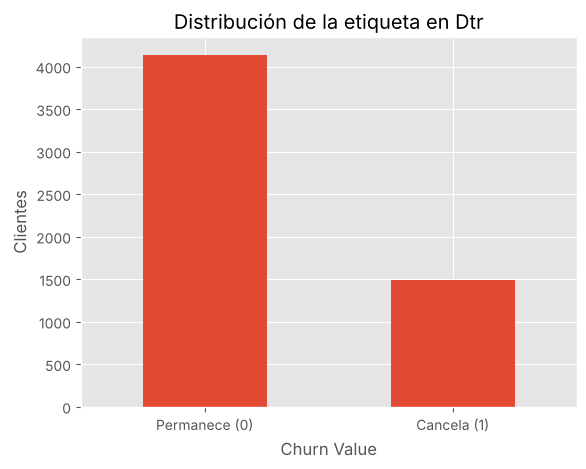

In [10]:
ytr.value_counts().sort_index().plot(kind='bar', rot=0)
plt.xticks([0, 1], ['Permanece (0)', 'Cancela (1)'])
plt.title('Distribución de la etiqueta en Dtr')
plt.ylabel('Clientes')
plt.show()

In [11]:
descriptivos = Xtr[num].describe().T
descriptivos['Asimetría'] = Xtr[num].skew()
display(descriptivos)

,count,mean,std,min,25%,50%,75%,max,Asimetría
Tenure Months,5634.0,32.4851,24.5687,0.0,9.0000,29.000,55.000,72.00,0.2374
Monthly Charges,5634.0,64.9300,30.1381,18.4,35.6625,70.500,90.000,118.75,-0.2244
Total Charges,5634.0,2299.3347,2279.2043,0.0,402.9750,1394.925,3835.825,8684.80,0.9490


Churn Value,0,1
Contract,,
Month-to-month,0.5725,0.4275
One year,0.8892,0.1108
Two year,0.9713,0.0287


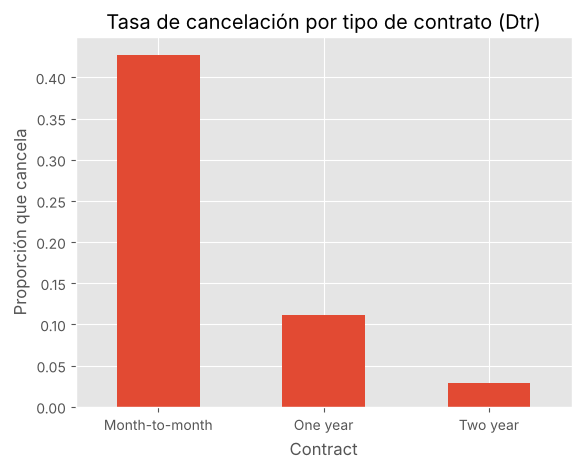

In [12]:
tabla_contrato = pd.crosstab(Xtr['Contract'], ytr, normalize='index')
display(tabla_contrato)

tabla_contrato[1].plot(kind='bar', rot=0)
plt.title('Tasa de cancelación por tipo de contrato (Dtr)')
plt.ylabel('Proporción que cancela')
plt.show()

In [13]:
datos_correlacion = Xtr[num].copy()
datos_correlacion['Churn Value'] = ytr
display(datos_correlacion.corr().round(3))

,Tenure Months,Monthly Charges,Total Charges,Churn Value
Tenure Months,1.000,0.257,0.830,-0.346
Monthly Charges,0.257,1.000,0.654,0.198
Total Charges,0.830,0.654,1.000,-0.194
Churn Value,-0.346,0.198,-0.194,1.000


No eliminamos clientes por tener valores extremos. La antigüedad y los cargos se mantienen en rangos
razonables, y un valor alejado del resto puede ser información válida. Tampoco tratamos como datos faltantes
categorías como `No internet service` o `No phone service`, porque indican que el cliente no tiene ese
servicio.

# 4. Preprocesamiento y diagnóstico de PCA

Las variables numéricas se estandarizan y las categóricas se codifican con one-hot. En las variables binarias
se conserva una sola columna, y una categoría que no apareció en el entrenamiento se representa con ceros.
Este preprocesamiento forma parte del pipeline de cada modelo, de modo que en la validación cruzada se ajusta
solo con los datos de entrenamiento de cada partición y no se filtra información de validación.

In [14]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

def prep():
    return ColumnTransformer([
        ('num', StandardScaler(), num),
        ('cat', OneHotEncoder(handle_unknown='ignore', drop='if_binary'), cat),
    ])

n_features = int(prep().fit(Xtr).transform(Xtr[:5]).shape[1])
print('Columnas tras codificar:', n_features)
print(list(prep().fit(Xtr).get_feature_names_out()))

Columnas tras codificar: 40
['num__Tenure Months', 'num__Monthly Charges', 'num__Total Charges', 'cat__Gender_Male', 'cat__Senior Citizen_Yes', 'cat__Partner_Yes', 'cat__Dependents_Yes', 'cat__Phone Service_Yes', 'cat__Multiple Lines_No', 'cat__Multiple Lines_No phone service', 'cat__Multiple Lines_Yes', 'cat__Internet Service_DSL', 'cat__Internet Service_Fiber optic', 'cat__Internet Service_No', 'cat__Online Security_No', 'cat__Online Security_No internet service', 'cat__Online Security_Yes', 'cat__Online Backup_No', 'cat__Online Backup_No internet service', 'cat__Online Backup_Yes', 'cat__Device Protection_No', 'cat__Device Protection_No internet service', 'cat__Device Protection_Yes', 'cat__Tech Support_No', 'cat__Tech Support_No internet service', 'cat__Tech Support_Yes', 'cat__Streaming TV_No', 'cat__Streaming TV_No internet service', 'cat__Streaming TV_Yes', 'cat__Streaming Movies_No', 'cat__Streaming Movies_No internet service', 'cat__Streaming Movies_Yes', 'cat__Contract_Month-

Como diagnóstico, revisamos cuánta varianza explican los componentes principales de las tres variables
numéricas. Aun así, mantenemos las 19 variables originales: el número es manejable, poder interpretar el
modelo por servicio es parte del objetivo y conservar la mayor varianza no garantiza una mejor predicción.

,Componente,Varianza explicada,Acumulada
0,1,0.7300,0.7300
1,2,0.2504,0.9805
2,3,0.0195,1.0000


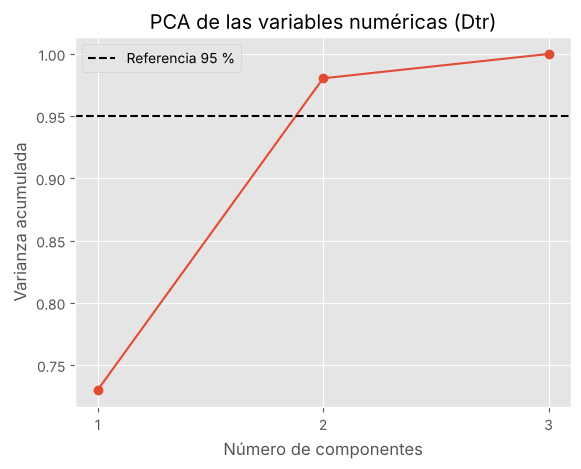

In [15]:
from sklearn.decomposition import PCA

pca = PCA().fit(StandardScaler().fit_transform(Xtr[num]))
varianza_acumulada = np.cumsum(pca.explained_variance_ratio_)
display(pd.DataFrame({'Componente': [1, 2, 3],
                      'Varianza explicada': pca.explained_variance_ratio_,
                      'Acumulada': varianza_acumulada}))

plt.plot([1, 2, 3], varianza_acumulada, '-o')
plt.axhline(0.95, color='black', linestyle='--', label='Referencia 95 %')
plt.xticks([1, 2, 3])
plt.xlabel('Número de componentes')
plt.ylabel('Varianza acumulada')
plt.title('PCA de las variables numéricas (Dtr)')
plt.legend()
plt.show()

# 5. Modelos y validación cruzada

Comparamos dos modelos con fronteras de decisión distintas: una regresión logística, lineal e interpretable,
y un árbol de decisión, capaz de capturar relaciones no lineales. Estas son las combinaciones de
hiperparámetros que se prueban:

| Modelo | Regla aprendida | Hiperparámetros probados | Combinaciones |
|---|---|---|---|
| Regresión logística | $P(y=1\mid x)=1/(1+e^{-\theta^Tx})$, con regularización L2 | `C` ∈ {0.01, 0.1, 1, 10, 100} | 5 |
| Árbol CART | Cortes que reducen la impureza de Gini $G=1-\sum_c p_c^2$ | profundidad ∈ {3, 4, 5, 6, 8, 10, sin límite} × mínimo por hoja ∈ {1, 5, 10, 20, 50} | 35 |

Los modelos se entrenan con la proporción real de clases (26,5 % de cancelaciones), sin sobremuestreo,
submuestreo ni pesos por clase. El desbalance se aborda únicamente con el umbral de decisión. Los pesos
balanceados y el submuestreo se evalúan más adelante, pero solo como puntos de comparación (E4).

In [16]:
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

modelos = {
    'RL': (LogisticRegression(max_iter=2000), {'clf__C': [0.01, 0.1, 1, 10, 100]}),
    'AD': (DecisionTreeClassifier(random_state=SEED),
           {'clf__max_depth': [3, 4, 5, 6, 8, 10, None], 'clf__min_samples_leaf': [1, 5, 10, 20, 50]}),
}
nombres_modelo = {'RL': 'Regresión logística', 'AD': 'Árbol de decisión'}

cv = StratifiedKFold(5, shuffle=True, random_state=SEED)

**E1.** Elegimos los hiperparámetros de cada modelo con una búsqueda en rejilla y validación cruzada
estratificada de 5 particiones sobre el conjunto de entrenamiento, maximizando el AUC. Usamos el AUC porque
mide qué tan bien el modelo ordena a los clientes según su riesgo, sin depender del umbral; el umbral se
decide en la sección siguiente.

In [17]:
busquedas, mejores, tiempos = {}, {}, {}

for nom, (clf, grid) in modelos.items():
    t0 = time.time()
    gs = GridSearchCV(Pipeline([('prep', prep()), ('clf', clf)]), grid,
                      scoring='roc_auc', cv=cv, n_jobs=-1)
    gs.fit(Xtr, ytr)
    tiempos[nom] = {'t_grid': time.time() - t0}
    busquedas[nom] = gs
    mejores[nom] = gs.best_estimator_

tabla_e1 = pd.DataFrame({
    'Modelo': [nombres_modelo[m] for m in modelos],
    'Mejores hiperparámetros': [busquedas[m].best_params_ for m in modelos],
    'AUC en VC': [busquedas[m].best_score_ for m in modelos],
    'Tiempo búsqueda (s)': [tiempos[m]['t_grid'] for m in modelos],
})
display(tabla_e1)

,Modelo,Mejores hiperparámetros,AUC en VC,Tiempo búsqueda (s)
0,Regresión logística,{'clf__C': 100},0.8590,1.7898
1,Árbol de decisión,"{'clf__max_depth': 6, 'clf__min_samples_leaf':...",0.8464,4.4259


### Sensibilidad a los hiperparámetros

AUC promedio de validación cruzada para cada combinación probada.

In [18]:
gsl = busquedas['RL'].cv_results_
c_tab = {str(p['clf__C']): float(s) for p, s in zip(gsl['params'], gsl['mean_test_score'])}
display(pd.Series(c_tab, name='AUC VC').rename_axis('C').to_frame())

gsd = busquedas['AD'].cv_results_
prof = pd.DataFrame({
    'max_depth': [str(p['clf__max_depth']) for p in gsd['params']],
    'min_leaf': [p['clf__min_samples_leaf'] for p in gsd['params']],
    'auc': gsd['mean_test_score'],
})
prof_tab = prof.pivot(index='max_depth', columns='min_leaf', values='auc')
display(prof_tab)

,AUC VC
C,
0.01,0.8531
0.1,0.8583
1,0.8589
10,0.8588
100,0.8590


min_leaf,1,5,10,20,50
max_depth,,,,,
10,0.7632,0.7916,0.8084,0.8250,0.8437
3,0.8194,0.8194,0.8194,0.8194,0.8194
4,0.8394,0.8394,0.8398,0.8398,0.8406
5,0.8445,0.8451,0.8449,0.8444,0.8459
6,0.8413,0.8420,0.8429,0.8433,0.8464
8,0.8131,0.8167,0.8208,0.8309,0.8441
None,0.6678,0.7685,0.8030,0.8229,0.8437


# 6. Umbrales y entrenamiento final

**E2.** Para calibrar el umbral necesitamos, para cada cliente de entrenamiento, una probabilidad que no
esté influida por ese mismo cliente. La obtenemos con validación cruzada anidada: en cada una de las 5
particiones externas repetimos la búsqueda de hiperparámetros de E1 usando solo las otras cuatro partes, y
el modelo resultante predice la parte que quedó fuera. Así, ningún cliente participa en el entrenamiento ni
en la elección de hiperparámetros del modelo que estima su probabilidad. Si usáramos probabilidades sobre
datos que el modelo ya vio, serían demasiado optimistas y el umbral quedaría mal elegido.

Con esas probabilidades, el umbral de cada modelo es el que maximiza F1:
$\tau^*=\arg\max_{\tau\in\{0.10,\ldots,0.90\}}F1(\tau)$. Si dos umbrales empatan, se toma el menor. El límite
de 5 puntos en la caída de precisión no entra en esta búsqueda; se usa después, para evaluar la hipótesis
en prueba.

In [19]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (recall_score, precision_score, f1_score, roc_auc_score,
                             accuracy_score, confusion_matrix, roc_curve)

def metricas(yt, p, tau):
    yp = (p >= tau).astype(int)
    tn, fp, fn, tp = confusion_matrix(yt, yp).ravel()
    return dict(tau=float(tau), recall=recall_score(yt, yp),
                precision=precision_score(yt, yp, zero_division=0),
                f1=f1_score(yt, yp), accuracy=accuracy_score(yt, yp), auc=roc_auc_score(yt, p),
                tp=int(tp), fp=int(fp), fn=int(fn), tn=int(tn))

def calibrar(p_oof, ytr):
    f1s = np.array([f1_score(ytr, (p_oof >= t).astype(int)) for t in GRID_TAU])
    return float(GRID_TAU[f1s.argmax()]), f1s

In [20]:
def probabilidades_oof(clf, grid, X_d, y_d, cv_ext, seed):
    # VC anidada: búsqueda interna en cada partición externa; devuelve probabilidades OOF
    p = np.zeros(len(y_d))
    elegidos = []
    for k, (i_tr, i_va) in enumerate(cv_ext.split(X_d, y_d)):
        cv_int = StratifiedKFold(5, shuffle=True, random_state=seed + 100 + k)
        gs_int = GridSearchCV(Pipeline([('prep', prep()), ('clf', clf)]), grid,
                              scoring='roc_auc', cv=cv_int, n_jobs=-1)
        gs_int.fit(X_d.iloc[i_tr], y_d.iloc[i_tr])
        p[i_va] = gs_int.predict_proba(X_d.iloc[i_va])[:, 1]
        elegidos.append(gs_int.best_params_)
    return p, elegidos

In [21]:
p_oof, taus, f1s_oof, params_externos = {}, {}, {}, {}

for nom, (clf, grid) in modelos.items():
    t0 = time.time()
    p_oof[nom], params_externos[nom] = probabilidades_oof(clf, grid, Xtr, ytr, cv, SEED)
    taus[nom], f1s_oof[nom] = calibrar(p_oof[nom], ytr)
    tiempos[nom]['t_cal'] = time.time() - t0

print('Hiperparámetros elegidos en cada partición externa:')
for nom in modelos:
    print(f'  {nombres_modelo[nom]}:', params_externos[nom])

tabla_e2 = pd.DataFrame([
    {'Modelo': nombres_modelo[m], 'Umbral': u, **metricas(ytr, p_oof[m], u)}
    for m in modelos for u in (0.5, taus[m])
])
display(tabla_e2[['Modelo', 'Umbral', 'recall', 'precision', 'f1', 'auc']])

Hiperparámetros elegidos en cada partición externa:
  Regresión logística: [{'clf__C': 10}, {'clf__C': 100}, {'clf__C': 100}, {'clf__C': 10}, {'clf__C': 100}]
  Árbol de decisión: [{'clf__max_depth': 10, 'clf__min_samples_leaf': 50}, {'clf__max_depth': 8, 'clf__min_samples_leaf': 50}, {'clf__max_depth': 5, 'clf__min_samples_leaf': 50}, {'clf__max_depth': 6, 'clf__min_samples_leaf': 50}, {'clf__max_depth': 6, 'clf__min_samples_leaf': 50}]


,Modelo,Umbral,recall,precision,f1,auc
0,Regresión logística,0.50,0.5846,0.6667,0.6230,0.8586
1,Regresión logística,0.32,0.7579,0.5696,0.6504,0.8586
2,Árbol de decisión,0.50,0.5291,0.6298,0.5751,0.8448
3,Árbol de decisión,0.36,0.7371,0.5628,0.6383,0.8448


### Figura 2: métricas en función del umbral

Recall, precisión y F1 calculados con las probabilidades fuera de muestra del conjunto de entrenamiento. La
línea punteada gris marca $\tau=0.5$ y la discontinua negra, $\tau^*$.

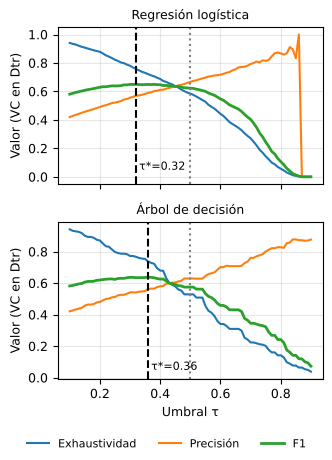

In [22]:
with plt.style.context('default'):
    plt.rcParams.update({'font.size': 9, 'font.family': 'DejaVu Sans'})
    fig, axes = plt.subplots(2, 1, figsize=(3.4, 4.6), sharex=True)
    for ax, nom in zip(axes, ['RL', 'AD']):
        p = p_oof[nom]
        pr = [precision_score(ytr, (p >= t).astype(int), zero_division=0) for t in GRID_TAU]
        rc = [recall_score(ytr, (p >= t).astype(int)) for t in GRID_TAU]
        ax.plot(GRID_TAU, rc, label='Exhaustividad', color='#1f77b4')
        ax.plot(GRID_TAU, pr, label='Precisión', color='#ff7f0e')
        ax.plot(GRID_TAU, f1s_oof[nom], label='F1', color='#2ca02c', lw=2)
        ax.axvline(0.5, ls=':', c='gray')
        ax.axvline(taus[nom], ls='--', c='k')
        ax.text(taus[nom] + 0.01, 0.05, f'τ*={taus[nom]:.2f}', fontsize=8)
        ax.set_title(nombres_modelo[nom], fontsize=9)
        ax.set_ylabel('Valor (VC en Dtr)')
        ax.grid(alpha=.3)
    axes[1].set_xlabel('Umbral τ')
    h, l = axes[0].get_legend_handles_labels()
    fig.legend(h, l, loc='lower center', ncol=3, fontsize=8, frameon=False)
    fig.tight_layout(rect=(0, 0.05, 1, 1))
    fig.savefig(carpeta_salida / 'fig2_umbral.png', dpi=200)
    plt.show()

Elegimos el modelo final usando solo el conjunto de entrenamiento: el que obtiene mayor F1 con su umbral
calibrado (si hubiera empate, el de mayor recall). Ambos modelos se evalúan en prueba, porque la pregunta de
investigación los incluye a los dos, pero esa evaluación no cambia la elección. El modelo final es el que se
usa en el análisis por grupos y en el ranking de la sección 8.

In [23]:
seleccion = pd.DataFrame([
    {'clave': m, 'Modelo': nombres_modelo[m], 'τ*': taus[m],
     'F1 OOF': metricas(ytr, p_oof[m], taus[m])['f1'],
     'Recall OOF': metricas(ytr, p_oof[m], taus[m])['recall']}
    for m in modelos
]).sort_values(['F1 OOF', 'Recall OOF', 'Modelo'], ascending=[False, False, True])
display(seleccion.drop(columns='clave'))

modelo_final = seleccion.iloc[0]['clave']
print('Modelo final elegido antes de abrir la prueba:', nombres_modelo[modelo_final],
      '· τ* =', taus[modelo_final])

,Modelo,τ*,F1 OOF,Recall OOF
0,Regresión logística,0.32,0.6504,0.7579
1,Árbol de decisión,0.36,0.6383,0.7371


Modelo final elegido antes de abrir la prueba: Regresión logística · τ* = 0.32


Por último, cada modelo se reentrena con todo el conjunto de entrenamiento usando los hiperparámetros
elegidos en E1. A partir de aquí, los umbrales y el modelo final quedan fijos.

In [24]:
for nom in modelos:
    t0 = time.time()
    mejores[nom].fit(Xtr, ytr)
    tiempos[nom]['t_fit'] = time.time() - t0

display(pd.DataFrame(tiempos).T.rename(index=nombres_modelo).round(3))

,t_grid,t_cal,t_fit
Regresión logística,1.790,3.475,0.043
Árbol de decisión,4.426,19.594,0.043


# 7. Evaluación final

**E3.** Recién ahora usamos el conjunto de prueba, con todas las decisiones ya tomadas. Evaluamos cuatro
escenarios: cada modelo con $\tau=0.5$ y con su $\tau^*$. Las métricas principales son el recall, que indica
qué proporción de los clientes que cancelan se detecta, y F1. La precisión muestra cuántas de las alertas
son correctas, y el AUC mide la capacidad de ordenar a los clientes, que no depende del umbral.

$\mathrm{Precision}=TP/(TP+FP)$, $\mathrm{Recall}=TP/(TP+FN)$,
$F1=2\,\mathrm{Precision}\,\mathrm{Recall}/(\mathrm{Precision}+\mathrm{Recall})$.

In [25]:
p_te, m05, mtau = {}, {}, {}
for nom in modelos:
    p_te[nom] = mejores[nom].predict_proba(Xte)[:, 1]
    m05[nom] = metricas(yte, p_te[nom], 0.5)
    mtau[nom] = metricas(yte, p_te[nom], taus[nom])

resultados_test = pd.DataFrame([
    {'Modelo': nombres_modelo[m], 'Escenario': esc, **met}
    for m in modelos for esc, met in [('τ = 0.5', m05[m]), ('τ*', mtau[m])]
])
display(resultados_test)

,Modelo,Escenario,tau,recall,precision,f1,accuracy,auc,tp,fp,fn,tn
0,Regresión logística,τ = 0.5,0.50,0.5668,0.6217,0.5930,0.7935,0.8477,212,129,162,906
1,Regresión logística,τ*,0.32,0.7326,0.5404,0.6220,0.7637,0.8477,274,233,100,802
2,Árbol de decisión,τ = 0.5,0.50,0.5722,0.6097,0.5903,0.7892,0.8391,214,137,160,898
3,Árbol de decisión,τ*,0.36,0.7273,0.5551,0.6296,0.7729,0.8391,272,218,102,817


### Matrices de confusión

Las filas son los valores reales y las columnas, las predicciones.

In [26]:
for nom in modelos:
    for etiqueta, met in [('τ = 0.5', m05[nom]), (f"τ* = {taus[nom]:.2f}", mtau[nom])]:
        matriz = pd.DataFrame([[met['tn'], met['fp']], [met['fn'], met['tp']]],
                              index=['Real 0', 'Real 1'], columns=['Pred 0', 'Pred 1'])
        print(f'{nombres_modelo[nom]} · {etiqueta}')
        display(matriz)

Regresión logística · τ = 0.5


,Pred 0,Pred 1
Real 0,906,129
Real 1,162,212


Regresión logística · τ* = 0.32


,Pred 0,Pred 1
Real 0,802,233
Real 1,100,274


Árbol de decisión · τ = 0.5


,Pred 0,Pred 1
Real 0,898,137
Real 1,160,214


Árbol de decisión · τ* = 0.36


,Pred 0,Pred 1
Real 0,817,218
Real 1,102,272


### Figura 3: curva ROC en prueba

Los círculos marcan el punto de operación con $\tau=0.5$ y los cuadrados, con $\tau^*$. Cambiar el umbral
solo desplaza el punto sobre la misma curva, por eso el AUC no cambia.

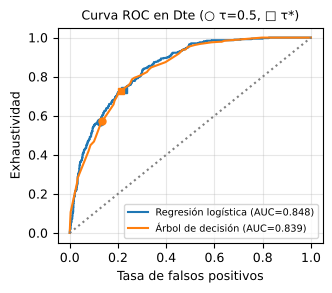

In [27]:
with plt.style.context('default'):
    plt.rcParams.update({'font.size': 9, 'font.family': 'DejaVu Sans'})
    fig, ax = plt.subplots(figsize=(3.4, 3.0))
    for nom in ['RL', 'AD']:
        fpr, tpr, _ = roc_curve(yte, p_te[nom])
        ax.plot(fpr, tpr, label=f"{nombres_modelo[nom]} (AUC={mtau[nom]['auc']:.3f})")
        for t, mk in [(0.5, 'o'), (taus[nom], 's')]:
            m = metricas(yte, p_te[nom], t)
            ax.plot(m['fp'] / (m['fp'] + m['tn']), m['recall'], mk, c=ax.lines[-1].get_color(), ms=5)
    ax.plot([0, 1], [0, 1], ':', c='gray')
    ax.set_xlabel('Tasa de falsos positivos')
    ax.set_ylabel('Exhaustividad')
    ax.legend(fontsize=7, loc='lower right')
    ax.set_title('Curva ROC en Dte (○ τ=0.5, □ τ*)', fontsize=9)
    ax.grid(alpha=.3)
    fig.tight_layout()
    fig.savefig(carpeta_salida / 'fig3_roc.png', dpi=200)
    plt.show()

Para contrastar la hipótesis calculamos, para cada modelo, cuánto cambian el recall y la precisión al pasar
de $\tau=0.5$ a $\tau^*$, en puntos porcentuales. La hipótesis se cumple si el recall aumenta y la precisión
no cae más de 5 puntos. Una mejora en F1, por sí sola, no basta. Este resultado corresponde a una sola
partición; más adelante se repite en 10.

In [28]:
hipotesis = pd.DataFrame({
    'Modelo': [nombres_modelo[m] for m in modelos],
    'τ*': [taus[m] for m in modelos],
    'ΔRecall (pp)': [100 * (mtau[m]['recall'] - m05[m]['recall']) for m in modelos],
    'ΔPrecision (pp)': [100 * (mtau[m]['precision'] - m05[m]['precision']) for m in modelos],
    'ΔF1 (pp)': [100 * (mtau[m]['f1'] - m05[m]['f1']) for m in modelos],
})
hipotesis['Cumple hipótesis'] = (hipotesis['ΔRecall (pp)'] > 0) & (hipotesis['ΔPrecision (pp)'] >= -5)
hipotesis['Modelo final'] = [m == modelo_final for m in modelos]
display(hipotesis)

,Modelo,τ*,ΔRecall (pp),ΔPrecision (pp),ΔF1 (pp),Cumple hipótesis,Modelo final
0,Regresión logística,0.32,16.5775,-8.1267,2.9013,False,True
1,Árbol de decisión,0.36,15.5080,-5.4585,3.9285,False,False


### Técnicas de referencia (E4)

Para poner los resultados en contexto, los comparamos con alternativas que no forman parte del método
propuesto:

| Referencia | Qué hace | Para qué sirve |
|---|---|---|
| Trivial | Marca a todos los clientes como desertores | Muestra que un recall de 1 no basta si la precisión es baja |
| Pesos balanceados | Da más peso a la clase minoritaria y usa $\tau=0.5$ | Es otra forma habitual de tratar el desbalance |
| Submuestreo y umbral calibrado | Reduce la clase mayoritaria y luego calibra $\tau$, como en Cao (2026) | Permite ver si submuestrear distorsiona las probabilidades |

In [29]:
import sklearn.base as skb

ref = {}
ref['Trivial (todos desertan)'] = metricas(yte, np.ones(len(yte)), 0.5)

for nom in ['RL', 'AD']:
    best = mejores[nom]

    # Pesos balanceados con los mismos hiperparámetros y τ = 0.5
    clf_bal = best.named_steps['clf'].__class__(
        **{**best.named_steps['clf'].get_params(), 'class_weight': 'balanced'})
    bw = Pipeline([('prep', prep()), ('clf', clf_bal)]).fit(Xtr, ytr)
    ref[f'{nom} + pesos balanceados (τ=0.5)'] = metricas(yte, bw.predict_proba(Xte)[:, 1], 0.5)

    # Submuestreo de la clase mayoritaria + umbral calibrado (procedimiento original de Cao)
    rng = np.random.RandomState(SEED)
    idx1 = np.where(ytr.values == 1)[0]
    idx0 = np.where(ytr.values == 0)[0]
    sel = np.concatenate([idx1, rng.choice(idx0, len(idx1), replace=False)])
    Xu, yu = Xtr.iloc[sel], ytr.iloc[sel]
    mu = skb.clone(best)
    pu = cross_val_predict(mu, Xu, yu, cv=StratifiedKFold(5, shuffle=True, random_state=SEED),
                           method='predict_proba')[:, 1]
    tau_u, _ = calibrar(pu, yu)
    mu.fit(Xu, yu)
    pu_te = mu.predict_proba(Xte)[:, 1]
    ref[f'{nom} + submuestreo + τ calibrado (Cao)'] = metricas(yte, pu_te, tau_u)
    ref[f'{nom} + submuestreo + τ calibrado (Cao)']['prob_media'] = float(pu_te.mean())
    ref[f'{nom} sin submuestreo'] = {'prob_media': float(p_te[nom].mean())}

tabla_ref = pd.DataFrame(ref).T
display(tabla_ref[['tau', 'recall', 'precision', 'f1', 'auc', 'prob_media']])
print('Tasa real de deserción en Dte:', round(yte.mean(), 4))

,tau,recall,precision,f1,auc,prob_media
Trivial (todos desertan),0.50,1.0000,0.2654,0.4195,0.5000,NaN
RL + pesos balanceados (τ=0.5),0.50,0.7781,0.5079,0.6146,0.8478,NaN
RL + submuestreo + τ calibrado (Cao),0.42,0.8583,0.4798,0.6155,0.8485,0.4060
RL sin submuestreo,NaN,NaN,NaN,NaN,NaN,0.2672
AD + pesos balanceados (τ=0.5),0.50,0.7754,0.5151,0.6190,0.8404,NaN
AD + submuestreo + τ calibrado (Cao),0.38,0.8957,0.4408,0.5908,0.8338,0.4056
AD sin submuestreo,NaN,NaN,NaN,NaN,NaN,0.2645


Tasa real de deserción en Dte: 0.2654


### Umbral restringido

Para comprobar si el límite de la hipótesis es alcanzable, buscamos el menor umbral cuya precisión, en
entrenamiento, no cae más de 5 puntos respecto a $\tau=0.5$. Igual que $\tau^*$, se elige solo con el
conjunto de entrenamiento y luego se evalúa en prueba.

In [30]:
restr = {}
for nom in ['RL', 'AD']:
    p = p_oof[nom]
    p05 = precision_score(ytr, (p >= 0.5).astype(int))
    ok = [t for t in GRID_TAU
          if precision_score(ytr, (p >= t).astype(int), zero_division=0) >= p05 - 0.05]
    tau_r = float(min(ok))
    restr[nom] = metricas(yte, p_te[nom], tau_r)

tabla_restr = pd.DataFrame(restr).T.rename(index=nombres_modelo)
tabla_restr['ΔRecall (pp)'] = [100 * (restr[m]['recall'] - m05[m]['recall']) for m in restr]
tabla_restr['ΔPrecision (pp)'] = [100 * (restr[m]['precision'] - m05[m]['precision']) for m in restr]
display(tabla_restr[['tau', 'recall', 'precision', 'f1', 'ΔRecall (pp)', 'ΔPrecision (pp)']])

,tau,recall,precision,f1,ΔRecall (pp),ΔPrecision (pp)
Regresión logística,0.42,0.6578,0.5928,0.6236,9.0909,-2.8930
Árbol de decisión,0.41,0.6578,0.5668,0.6089,8.5561,-4.2866


### Robustez en 10 particiones (E5)

Un resultado obtenido con una sola partición podría deberse al azar. Por eso repetimos todo el proceso
(partición, búsqueda de hiperparámetros, calibración del umbral, elección del modelo final y evaluación) con
10 particiones distintas, usando las semillas 42 a 51. Antes comprobamos que, con la semilla 42, la función
reproduce exactamente los resultados anteriores.

In [31]:
def correr(seed):
    Xtr_s, Xte_s, ytr_s, yte_s = train_test_split(X, y, test_size=0.2, stratify=y, random_state=seed)
    cv_s = StratifiedKFold(5, shuffle=True, random_state=seed)
    res = {}
    for nom, (clf, grid) in modelos.items():
        gs = GridSearchCV(Pipeline([('prep', prep()), ('clf', clf)]), grid,
                          scoring='roc_auc', cv=cv_s, n_jobs=-1)
        gs.fit(Xtr_s, ytr_s)
        best = gs.best_estimator_
        p_oof_s, _ = probabilidades_oof(clf, grid, Xtr_s, ytr_s, cv_s, seed)
        tau, _ = calibrar(p_oof_s, ytr_s)
        p_te_s = best.predict_proba(Xte_s)[:, 1]
        oof = metricas(ytr_s, p_oof_s, tau)
        res[nom] = dict(params=gs.best_params_, cv_auc=gs.best_score_, tau=tau,
                        f1_oof=oof['f1'], rec_oof=oof['recall'],
                        m05=metricas(yte_s, p_te_s, 0.5), mtau=metricas(yte_s, p_te_s, tau))
    res['final'] = sorted(modelos, key=lambda m: (-res[m]['f1_oof'], -res[m]['rec_oof'], nombres_modelo[m]))[0]
    return res

r42 = correr(SEED)
for nom in modelos:
    assert r42[nom]['tau'] == taus[nom]
    assert np.isclose(r42[nom]['mtau']['f1'], mtau[nom]['f1'])
assert r42['final'] == modelo_final
print('La semilla 42 reproduce los resultados de las secciones 5–7.')

La semilla 42 reproduce los resultados de las secciones 5–7.


In [32]:
rob = []
for s in range(10):
    r = r42 if s == 0 else correr(SEED + s)
    for nom in ['RL', 'AD']:
        rob.append(dict(seed=SEED + s, modelo=nom, tau=r[nom]['tau'],
                        rec05=r[nom]['m05']['recall'], recT=r[nom]['mtau']['recall'],
                        pre05=r[nom]['m05']['precision'], preT=r[nom]['mtau']['precision'],
                        f105=r[nom]['m05']['f1'], f1T=r[nom]['mtau']['f1'], auc=r[nom]['mtau']['auc'],
                        final=(r['final'] == nom)))

rob = pd.DataFrame(rob)
rob['d_rec'] = rob.recT - rob.rec05
rob['d_pre'] = rob.preT - rob.pre05
rob['d_f1'] = rob.f1T - rob.f105
rob.to_csv(carpeta_salida / 'robustez_10_semillas.csv', index=False)
display(rob.round(4))

,seed,modelo,tau,rec05,recT,pre05,preT,f105,f1T,auc,final,d_rec,d_pre,d_f1
0,42,RL,0.32,0.5668,0.7326,0.6217,0.5404,0.5930,0.6220,0.8477,True,0.1658,-0.0813,0.0290
1,42,AD,0.36,0.5722,0.7273,0.6097,0.5551,0.5903,0.6296,0.8391,False,0.1551,-0.0546,0.0393
2,43,RL,0.35,0.5802,0.7166,0.6911,0.5929,0.6308,0.6489,0.8697,True,0.1364,-0.0982,0.0181
3,43,AD,0.33,0.5508,0.7139,0.6378,0.5657,0.5911,0.6312,0.8568,False,0.1631,-0.0721,0.0401
4,44,RL,0.35,0.5775,0.7433,0.6814,0.5991,0.6252,0.6635,0.8705,True,0.1658,-0.0823,0.0383
5,44,AD,0.31,0.4626,0.7540,0.6578,0.5629,0.5432,0.6446,0.8471,False,0.2914,-0.0949,0.1014
6,45,RL,0.31,0.5749,0.7620,0.6380,0.5408,0.6048,0.6326,0.8419,True,0.1872,-0.0972,0.0278
7,45,AD,0.33,0.5134,0.7754,0.6076,0.5216,0.5565,0.6237,0.8342,False,0.2620,-0.0860,0.0671
8,46,RL,0.34,0.5802,0.7193,0.6616,0.5558,0.6182,0.6270,0.8477,True,0.1390,-0.1058,0.0088
9,46,AD,0.32,0.5160,0.7540,0.6287,0.5203,0.5668,0.6157,0.8282,False,0.2380,-0.1084,0.0489


In [33]:
rob_sum = rob.groupby('modelo')[['tau', 'rec05', 'recT', 'pre05', 'preT', 'f105', 'f1T',
                                 'auc', 'd_rec', 'd_pre', 'd_f1']].agg(['mean', 'std'])
display(rob_sum.round(3).T)

hip_cumple = {m: int(((rob.modelo == m) & (rob.d_rec > 0) & (rob.d_pre >= -0.05)).sum())
              for m in ['RL', 'AD']}
print('Particiones (de 10) en que se cumple la hipótesis completa:', hip_cumple)

veces_final = rob[rob.final].modelo.value_counts().reindex(['RL', 'AD'], fill_value=0).to_dict()
print('Particiones (de 10) en que cada modelo resulta elegido como final:', veces_final)
d_final = rob[rob.final]
print('Modelo final en cada partición · cumple la hipótesis en:',
      int(((d_final.d_rec > 0) & (d_final.d_pre >= -0.05)).sum()), 'de 10')

modelo         AD     RL
tau   mean  0.328  0.342
      std   0.023  0.028
rec05 mean  0.539  0.575
      std   0.057  0.008
recT  mean  0.734  0.729
      std   0.040  0.029
pre05 mean  0.609  0.648
      std   0.030  0.027
preT  mean  0.544  0.567
      std   0.021  0.026
f105  mean  0.569  0.609
      std   0.027  0.015
f1T   mean  0.624  0.637
      std   0.012  0.017
auc   mean  0.837  0.852
      std   0.009  0.011
d_rec mean  0.195  0.154
      std   0.081  0.031
d_pre mean -0.065 -0.081
      std   0.031  0.017
d_f1  mean  0.054  0.028
      std   0.030  0.013

Particiones (de 10) en que se cumple la hipótesis completa: {'RL': 0, 'AD': 3}
Particiones (de 10) en que cada modelo resulta elegido como final: {'RL': 10, 'AD': 0}
Modelo final en cada partición · cumple la hipótesis en: 0 de 10


### Figura 4: robustez

Cada punto representa una partición y muestra cuánto cambian la precisión y el recall al pasar de $\tau=0.5$
a $\tau^*$. La línea discontinua marca el límite de −5 puntos en precisión.

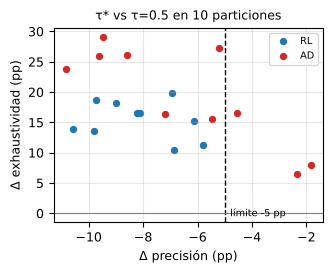

In [34]:
with plt.style.context('default'):
    plt.rcParams.update({'font.size': 9, 'font.family': 'DejaVu Sans'})
    fig, ax = plt.subplots(figsize=(3.4, 2.8))
    for nom, c in [('RL', '#1f77b4'), ('AD', '#d62728')]:
        d = rob[rob.modelo == nom]
        ax.scatter(d.d_pre * 100, d.d_rec * 100, label=nom, c=c, s=18)
    ax.axvline(-5, ls='--', c='k', lw=1)
    ax.axhline(0, c='gray', lw=.8)
    ax.text(-4.8, ax.get_ylim()[0] + 1 if ax.get_ylim()[0] < 0 else 1, 'límite -5 pp', fontsize=7)
    ax.set_xlabel('Δ precisión (pp)')
    ax.set_ylabel('Δ exhaustividad (pp)')
    ax.set_title('τ* vs τ=0.5 en 10 particiones', fontsize=9)
    ax.legend(fontsize=7)
    ax.grid(alpha=.3)
    fig.tight_layout()
    fig.savefig(carpeta_salida / 'fig4_robustez.png', dpi=200)
    plt.show()

# 8. Interpretación y ranking

Los coeficientes de la regresión logística y las importancias del árbol muestran qué variables pesan más en
cada modelo. Son asociaciones, no efectos causales: no implican que cambiar un servicio vaya a evitar una
cancelación. Como las variables numéricas están estandarizadas, su coeficiente corresponde al cambio de una
desviación estándar. En el árbol, la importancia de Gini puede favorecer a las variables que ofrecen más
puntos de corte.

,Coeficiente
num__Monthly Charges,-2.1378
cat__Dependents_Yes,-1.6462
num__Tenure Months,-1.3214
cat__Internet Service_DSL,-1.2634
cat__Multiple Lines_No phone service,-0.8913
cat__Contract_Two year,-0.8887
cat__Multiple Lines_Yes,0.4103
cat__Streaming Movies_Yes,0.4485
cat__Contract_Month-to-month,0.4501
cat__Streaming TV_Yes,0.4593


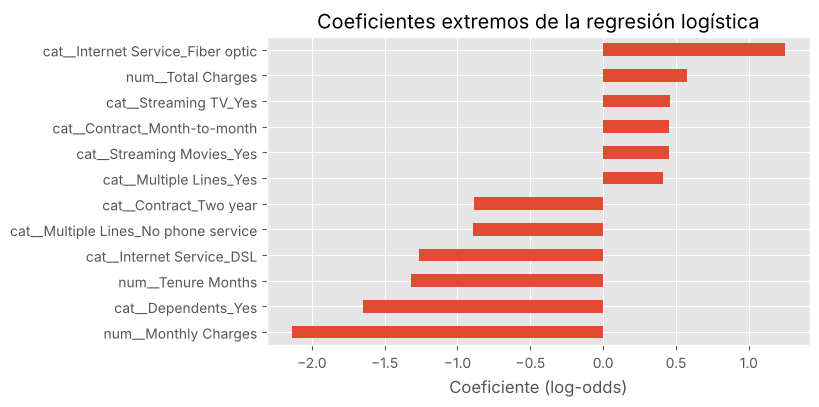

In [35]:
rl = mejores['RL']
coef = pd.Series(rl.named_steps['clf'].coef_[0],
                 index=rl.named_steps['prep'].get_feature_names_out()).sort_values()

extremos = pd.concat([coef.head(6), coef.tail(6)])
display(extremos.rename('Coeficiente').to_frame())

extremos.plot(kind='barh', figsize=(7, 4))
plt.title('Coeficientes extremos de la regresión logística')
plt.xlabel('Coeficiente (log-odds)')
plt.show()

In [36]:
ad = mejores['AD']
imp = pd.Series(ad.named_steps['clf'].feature_importances_,
                index=ad.named_steps['prep'].get_feature_names_out()).sort_values(ascending=False)
display(imp.head(10).rename('Importancia').to_frame())

,Importancia
cat__Contract_Month-to-month,0.4645
cat__Internet Service_Fiber optic,0.1475
num__Tenure Months,0.1451
cat__Dependents_Yes,0.0800
num__Total Charges,0.0485
num__Monthly Charges,0.0420
cat__Payment Method_Electronic check,0.0228
cat__Tech Support_No,0.0216
cat__Online Backup_No,0.0082
cat__Online Security_No,0.0078


### Priorización

Si el presupuesto de retención solo alcanza para contactar a una parte de los clientes, importa qué tan bien
el puntaje concentra a los desertores en los primeros lugares. Medimos qué porcentaje de los clientes de
prueba que cancelaron aparece dentro del 10 %, 20 % y 30 % con mayor riesgo estimado.

In [37]:
def captura(p, yt, k):
    n = int(np.ceil(len(p) * k))
    idx = np.argsort(-p)[:n]
    return float(yt.values[idx].sum() / yt.sum())

prior = {nom: {f'top{int(k * 100)}': captura(p_te[nom], yte, k) for k in [0.1, 0.2, 0.3]}
         for nom in ['RL', 'AD']}
display(pd.DataFrame(prior).rename(columns=nombres_modelo))

,Regresión logística,Árbol de decisión
top10,0.2861,0.2861
top20,0.5053,0.4733
top30,0.6604,0.6390


### Análisis por grupos (E6)

Revisamos el desempeño del modelo final, con su umbral calibrado, por género y por condición de adulto
mayor. Se usa el mismo umbral para todos y se comparan el recall, la precisión y la proporción de clientes
que reciben una alerta. Es un análisis descriptivo que no modifica el modelo. El conjunto de datos no incluye
la edad exacta, y las diferencias que aparezcan requieren más análisis: no prueban por sí solas un trato
injusto.

In [38]:
mejor = modelo_final   # elegido en la sección 6, solo con Dtr
print('Modelo revisado:', nombres_modelo[mejor], '· τ* =', taus[mejor])

equidad = {}
for col in ['Gender', 'Senior Citizen']:
    for g in sorted(Xte[col].unique()):
        msk = (Xte[col] == g).values
        yp = (p_te[mejor][msk] >= taus[mejor]).astype(int)
        equidad[f'{col}={g}'] = dict(n=int(msk.sum()), tasa_real=float(yte[msk].mean()),
                                    recall=recall_score(yte[msk], yp),
                                    precision=precision_score(yte[msk], yp),
                                    tasa_alerta=float(yp.mean()))
display(pd.DataFrame(equidad).T)

Modelo revisado: Regresión logística · τ* = 0.32


,n,tasa_real,recall,precision,tasa_alerta
Gender=Female,687.0,0.2809,0.7202,0.5605,0.3610
Gender=Male,722.0,0.2507,0.7459,0.5212,0.3587
Senior Citizen=No,1187.0,0.2325,0.6957,0.5203,0.3109
Senior Citizen=Yes,222.0,0.4414,0.8367,0.5942,0.6216


### Ranking de riesgo en prueba

Con el modelo final ordenamos a los clientes de prueba de mayor a menor riesgo. El `CLTV` se muestra como
referencia y sirve para desempatar, pero no se usa para predecir. Como los datos son históricos, la lista
incluye clientes que ya cancelaron; para una campaña real haría falta aplicar el modelo a clientes vigentes
y validarlo en el tiempo.

In [39]:
ranking_test = pd.DataFrame({
    'CustomerID': ids.loc[Xte.index].values,
    'Riesgo_estimado': p_te[mejor],
    'Alerta (≥ τ*)': (p_te[mejor] >= taus[mejor]).astype(int),
    'CLTV': cltv.loc[Xte.index].values,
    'Real': yte.values,
}).sort_values(['Riesgo_estimado', 'CLTV'], ascending=[False, False])

display(ranking_test.head(10))

,CustomerID,Riesgo_estimado,Alerta (≥ τ*),CLTV,Real
1090,5178-LMXOP,0.8784,1,5795,1
1175,6861-XWTWQ,0.8573,1,2487,1
1355,6630-UJZMY,0.8559,1,5251,0
51,7181-BQYBV,0.8403,1,4811,1
1138,1400-MMYXY,0.8386,1,2715,1
1221,0295-PPHDO,0.8376,1,5962,1
1164,8884-ADFVN,0.8335,1,2016,1
995,8161-QYMTT,0.8272,1,5259,0
234,7180-PISOG,0.8272,1,5554,1
41,4927-WWOOZ,0.8261,1,4889,0


### Guardar resultados

Guardamos todas las métricas en `resultados.json`.

In [40]:
info = dict(n=len(df), n_tr=len(Xtr), n_te=len(Xte), tasa=float(y.mean()), tasa_tr=float(ytr.mean()),
            tasa_te=float(yte.mean()), n_vacios_tc=n_vacios, n_features=n_features)

principal = {m: dict(params=busquedas[m].best_params_, cv_auc=busquedas[m].best_score_, tau=taus[m],
                     m05=m05[m], mtau=mtau[m],
                     oof05=metricas(ytr, p_oof[m], 0.5), oofTau=metricas(ytr, p_oof[m], taus[m]),
                     **tiempos[m])
             for m in ['RL', 'AD']}

salida = dict(info=info, restringido=restr, principal=principal, referencias=ref,
              c_tab=c_tab, prof_tab=prof_tab.round(4).to_dict(), priorizacion=prior, equidad=equidad,
              mejor=mejor, modelo_final=modelo_final, params_externos=params_externos,
              veces_final=veces_final, coef_top_pos=coef.tail(6).round(3).to_dict(),
              coef_top_neg=coef.head(6).round(3).to_dict(), imp_ad=imp.head(6).round(3).to_dict(),
              robustez={f'{a}_{b}': v for (a, b), v in rob_sum.round(4).to_dict().items()},
              hip_cumple=hip_cumple)

(carpeta_salida / 'resultados.json').write_text(
    json.dumps(salida, indent=2, ensure_ascii=False, default=str), encoding='utf-8')
print('Archivos generados:', sorted(p.name for p in carpeta_salida.iterdir()))

Archivos generados: ['fig2_umbral.png', 'fig3_roc.png', 'fig4_robustez.png', 'resultados.json', 'robustez_10_semillas.csv']


### Conclusiones

La búsqueda de hiperparámetros eligió `C = 100` para la regresión logística (AUC de validación 0,859) y, para
el árbol, una profundidad de 6 con un mínimo de 50 clientes por hoja (AUC de validación 0,846). Los umbrales
calibrados fueron 0,32 y 0,36. Con solo el conjunto de entrenamiento se eligió como modelo final la regresión
logística (F1 de 0,650 frente a 0,638), y fue también la elegida en las 10 particiones del análisis de
robustez.

En prueba, el umbral calibrado aumentó el recall del modelo final de 0,567 a 0,733 (+16,6 puntos) y su F1 de
0,593 a 0,622. Sin embargo, la precisión cayó 8,1 puntos, más que el límite planteado, por lo que **la hipótesis
no se cumple**. El árbol siguió el mismo patrón, con +15,5 puntos de recall y −5,5 de precisión, muy cerca del
límite. En ambos casos el AUC (0,848 y 0,839) no cambia, porque solo se mueve el punto de corte.

Las comparaciones ayudan a entender este resultado. Marcar a todos como desertores logra un recall de 1, pero
con una precisión de 0,265. Los pesos balanceados dan resultados parecidos a los del umbral calibrado. El
submuestreo detecta más desertores, pero eleva la probabilidad media predicha a cerca de 0,41 cuando la tasa
real es 0,265, y reduce aún más la precisión, lo que confirma la decisión de no submuestrear. El umbral
restringido muestra que el límite sí es alcanzable: con $\tau=0{,}42$, el modelo final gana 9,1 puntos de
recall perdiendo solo 2,9 de precisión, aunque la mejora es menor que con $\tau^*$.

Al repetir el experimento en 10 particiones, el patrón se mantiene: con el modelo final, el umbral calibrado
sube el recall en 15,4 puntos en promedio (desviación de 3,1) y reduce la precisión en 8,1, y la hipótesis no
se cumple en ninguna partición. El árbol la cumple en 3 de las 10, con resultados más variables. Esto indica
que la conclusión no depende de la partición elegida: calibrar el umbral intercambia precisión por recall de
forma estable.

En el análisis por grupos, el modelo final alerta al 62 % de los adultos mayores y al 31 % del resto, lo que
coincide con su mayor tasa real de cancelación (0,44 frente a 0,23). Entre hombres y mujeres las diferencias
son pequeñas. Estos resultados tienen límites: los datos corresponden a clientes de California y no incluyen
fechas, las probabilidades son estimaciones y las asociaciones no prueban causalidad. Para usar el modelo en
una campaña real haría falta aplicarlo a clientes vigentes y validarlo en el tiempo.